# Figures – Global Disease Network

Figures for the report and the presentation. Run `network_builder.py` first – this notebook reads the cleaned dataset and the network files it exported.

## 0 Setup

In [11]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

import build_network as nb

In [12]:
# Data and output locations
DATA_FILE = Path("./../data/processed/clean_2019.csv")
NETWORK_DIR = Path("./../data/network")

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # Match the viewer palette.

COMMUNITY_NAMES = {
    1: "Cancers",
    2: "Low-mortality",
    3: "Mixed chronic",
    4: "Maternal & tropical",
    5: "Infections & digestive",
    6: "Malnutrition & diarrhoea",
    7: "Heart & injuries",
    8: "Alcohol & liver",
    9: "Vaccine-preventable & TB",
    10: "HIV & violence",
    11: "Drug use & head-neck cancer",
}

PAIRS = [
    ("hiv_aids", "drowning"),
    ("alcohol_use_disorders", "cirrhosis_due_to_alcohol_use"),
    ("measles", "whooping_cough"),
    ("trachea_bronchus_lung_cancers", "chronic_obstructive_pulmonary_disease"),
]

SHORT = {
    "hiv_aids": "HIV",
    "tuberculosis": "TB",
    "trachea_bronchus_lung_cancers": "lung cancer",
    "chronic_obstructive_pulmonary_disease": "COPD",
    "alcohol_use_disorders": "alcohol use",
    "cirrhosis_due_to_alcohol_use": "cirrhosis (alcohol)",
    "cirrhosis_due_to_hepatitis_b": "cirrhosis (hep B)",
    "liver_cancer_secondary_to_hepatitis_b": "liver cancer (hep B)",
    "diabetes_mellitus": "diabetes",
    "chronic_kidney_disease_due_to_diabetes": "CKD (diabetes)",
    "other_chronic_kidney_disease": "other CKD",
    "ischaemic_heart_disease": "heart disease",
    "ischaemic_stroke": "stroke",
    "cervix_uteri_cancer": "cervical cancer",
    "maternal_conditions": "maternal",
    "birth_asphyxia_and_birth_trauma": "birth asphyxia",
    "neonatal_sepsis_and_infections": "neonatal sepsis",
    "diarrhoeal_diseases": "diarrhoea",
    "protein_energy_malnutrition": "malnutrition",
    "collective_violence_and_legal_intervention": "conflict",
    "dtp3_coverage": "DTP3",
    "measles_coverage": "measles vacc.",
    "skilled_birth_attendance": "birth attendance",
    "basic_water_access": "water",
    "basic_sanitation_access": "sanitation",
    "avail_dialysis": "dialysis",
    "avail_insulin": "insulin",
    "avail_thrombolysis": "thrombolysis",
    "avail_coronary_bypass_stent": "stents",
    "avail_cervical_cytology": "cervical screening",
    "avail_bronchodilators": "bronchodilators",
    "tb_incidence": "TB incidence",
    "hiv_prevalence_15_49": "HIV prevalence",
    "hepb_prevalence": "hep B",
    "alcohol_per_capita": "alcohol",
    "tobacco_prevalence": "tobacco",
    "pm25_exposure": "PM2.5",
    "raised_glucose_prevalence": "glucose",
    "obesity_prevalence": "obesity",
    "stunting_prevalence": "stunting",
    "battle_deaths_per100k": "battle deaths",
}

plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True, "legend.frameon": False}
)


def short(name):
    """Return a readable chart label for a cause or indicator."""
    key = name.replace("death_asdr_", "").replace(" ", "_")
    return SHORT.get(key, key.replace("_", " "))

### Load data

Loads data from network_builder and created data files

In [13]:
data = pd.read_csv(DATA_FILE)
causes = [c for c in data.columns if c.startswith("death_asdr_")]
residuals = nb.remove_control(data[causes], data[nb.CONTROL])

raw = data[causes].corr(method="spearman")
adjusted = residuals.corr()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    direct, alpha = nb.direct_links(residuals)

nodes = pd.read_csv(NETWORK_DIR / "nodes_glasso.csv")
edges = {
    method: pd.read_csv(NETWORK_DIR / f"edges_{method}.csv")
    for method in ("correlation", "glasso")
}
expected = pd.read_csv(NETWORK_DIR / "expected_links.csv")
cause_nodes = nodes[nodes["type"] == "cause"].set_index("id")
print(f"{len(data)} countries, {len(causes)} causes, alpha = {alpha:.3f}")

182 countries, 139 causes, alpha = 0.190


## 1 Wealth effect

Cause correlation after removing GDP. Spreaman gets better for GDP adjusted data

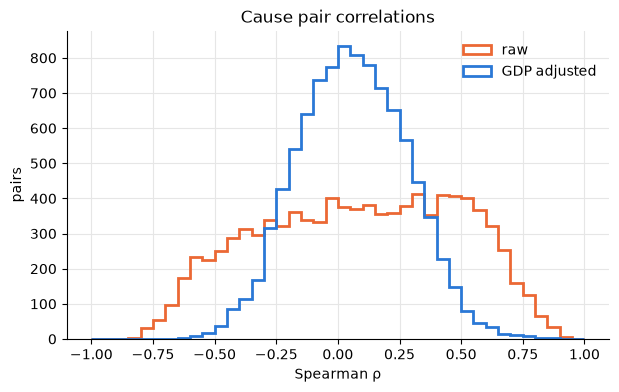

In [14]:
upper = np.triu_indices(len(causes), k=1)  # Count each pair once.

fig, ax = plt.subplots(figsize=(7, 4))
for matrix, color, name in [(raw, COLORS[1], "raw"), (adjusted, COLORS[0], "GDP adjusted")]:
    values = matrix.values[upper]
    ax.hist(values, bins=40, range=(-1, 1), histtype="step", linewidth=2, color=color, label=name)
ax.set_xlabel("Spearman ρ")
ax.set_ylabel("pairs")
ax.set_title("Cause pair correlations")
ax.legend()
plt.show()

## 2 Link strength of example pairs

- HIV – drowning: both high in southern Africa, no direct link.
- Alcohol use – cirrhosis (alcohol): survives every step.
- Measles – whooping cough: explained by the other vaccine-preventable diseases.
- Lung cancer – COPD: shared cause (smoking) but weak.

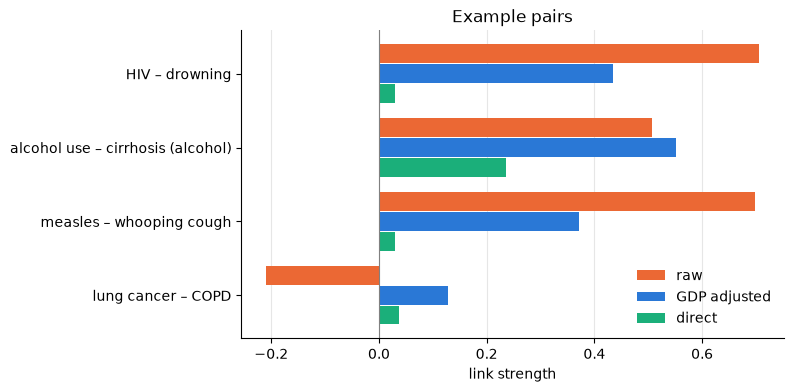

In [15]:
y = np.arange(len(PAIRS))
steps = [(raw, COLORS[1], "raw"), (adjusted, COLORS[0], "GDP adjusted"), (direct, COLORS[2], "direct")]

fig, ax = plt.subplots(figsize=(7, 4))
for k, (matrix, color, name) in enumerate(steps):
    values = [
        matrix.loc[f"death_asdr_{a}", f"death_asdr_{b}"]
        for a, b in PAIRS
    ]
    ax.barh(y + (k - 1) * 0.27, values, height=0.25, color=color, label=name)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_yticks(y, [f"{short(a)} – {short(b)}" for a, b in PAIRS])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("link strength")
ax.set_title("Example pairs")
ax.legend()
plt.show()

## 3 Direct-link network

Colour = community, size = number of links. Links inside a community pull harder in the layout so the communities are visible.

In [16]:
# layout (used again in figure 6)
community = cause_nodes["community"]
G = nx.Graph()
G.add_nodes_from(cause_nodes.index)
links = edges["glasso"][edges["glasso"]["type"] == "cause-cause"]
for source, target, weight in links[["source", "target", "weight"]].itertuples(index=False):
    same_community = community[source] == community[target]
    pull = weight * (15 if same_community else 1)
    G.add_edge(source, target, weight=weight, pull=pull)
pos = nx.spring_layout(G, weight="pull", seed=42, k=0.3, iterations=500)

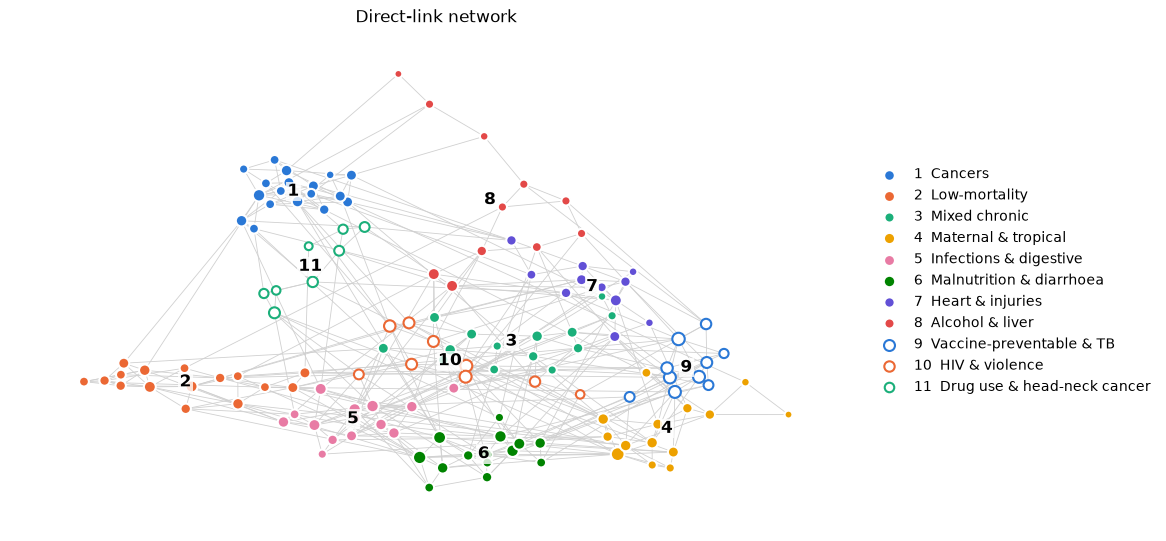

In [17]:
fig, ax = plt.subplots(figsize=(11, 6.5))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#d0d0d0", width=0.6)
for c, group in cause_nodes.groupby("community"):
    color = COLORS[(c - 1) % len(COLORS)]
    ring = c > len(COLORS)
    ax.scatter(
        [pos[node][0] for node in group.index],
        [pos[node][1] for node in group.index],
        s=20 + 6 * group["degree"],
        c="white" if ring else color,
        edgecolors=color if ring else "white",
        linewidths=1.5,
        zorder=3,
        label=f"{c}  {COMMUNITY_NAMES[c]}",
    )
    x, y = np.mean([pos[n] for n in group.index], axis=0)
    ax.text(x, y, c, fontsize=12, fontweight="bold", ha="center", va="center", zorder=4, bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
ax.set_axis_off()
ax.set_title("Direct-link network")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

### 4 Community stability

Represents how often the community stayed together of the total of 200 rebuilds. 

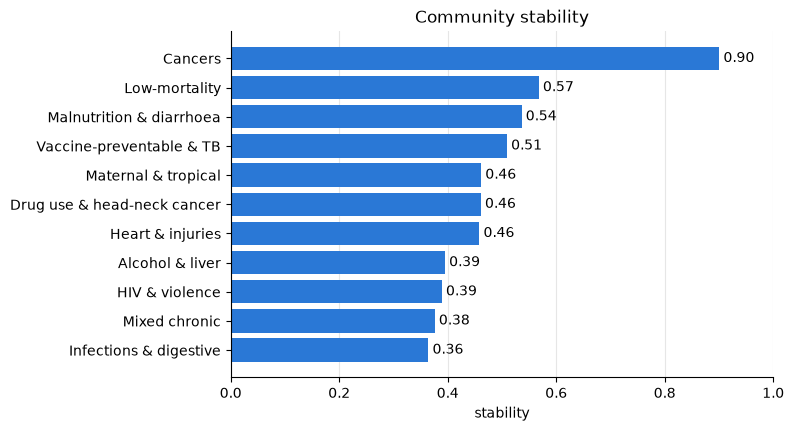

In [18]:
stability = cause_nodes.groupby("community")["stability"].mean().sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.barh([COMMUNITY_NAMES[c] for c in stability.index], stability, color=COLORS[0])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("stability")
ax.set_title("Community stability")
plt.show()

## 5 Expected indicator links

29 indicator -> cause links expected from medical knowledge. Dot = Spearman p with GDP removed, dashed = network threshold.

23 of 29 have the expected sign, 11 pass the threshold. Risk factors link strongly, coverage moderately (vaccination, sanitation), treatment availability not at all

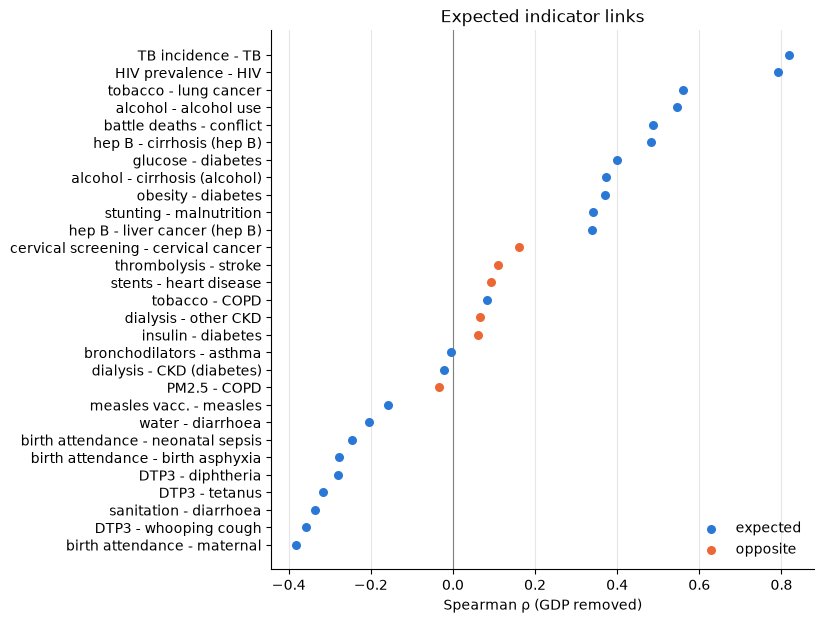

In [19]:
table = expected.sort_values("rho")
labels = [f"{short(i)} - {short(c)}" for i, c in zip(table["indicator"], table["cause"])]
y = np.arange(len(table))

fig, ax = plt.subplots(figsize=(7, 7))
for right, color, name in [(True, COLORS[0], "expected"), (False, COLORS[1], "opposite")]:
    part = (table["right_direction"] == right).values
    ax.scatter(table["rho"][part], y[part], s=30, color=color, label=name, zorder=3)

ax.axvline(0, color="grey", linewidth=0.8)
ax.set_yticks(y, labels)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Spearman ρ (GDP removed)")
ax.set_title("Expected indicator links")
ax.legend(loc="lower right")
plt.show()

## 6 Co-occurrence vs direct links

Creates a visual representation of links

Same node positions as figure 3, colour = WHO cause group. Grey = link in both networks, red = only in this one.

The co-occurrence network has about twice as many links, most within the poverty block.

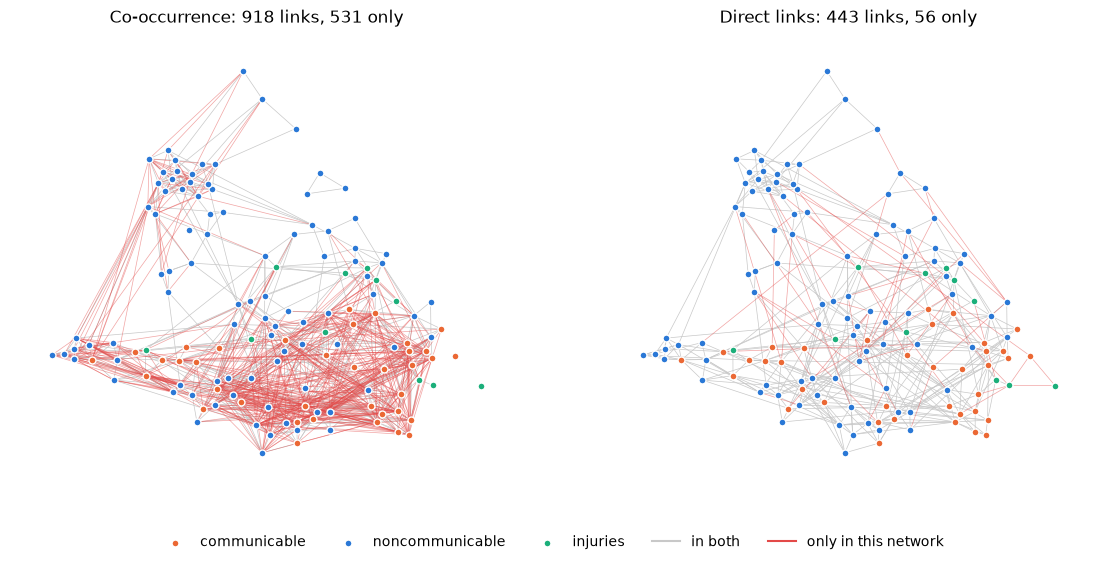

In [20]:
link_sets = {
    method: {
        frozenset(edge)
        for edge in frame.loc[frame["type"] == "cause-cause", ["source", "target"]].itertuples(index=False, name=None)
    }
    for method, frame in edges.items()
}
category_colors = {"communicable": COLORS[1], "noncommunicable": COLORS[0], "injuries": COLORS[2]}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, method, other_method, title in [(axes[0], "correlation", "glasso", "Co-occurrence"), (axes[1], "glasso", "correlation", "Direct links")]:
    both = [tuple(edge) for edge in link_sets[method] & link_sets[other_method]]
    only = [tuple(edge) for edge in link_sets[method] - link_sets[other_method]]

    nx.draw_networkx_edges(G, pos, edgelist=both, ax=ax, edge_color="#c8c8c8", width=0.5)
    nx.draw_networkx_edges(G, pos, edgelist=only, ax=ax, edge_color=COLORS[7], width=0.5, alpha=0.5)

    for category, color in category_colors.items():
        members = cause_nodes.index[cause_nodes["category"] == category]
        ax.scatter([pos[node][0] for node in members], [pos[node][1] for node in members], s=25, c=color, edgecolors="white", zorder=3, label=category)

        
    ax.set_title(f"{title}: {len(link_sets[method])} links, {len(only)} only")
    ax.set_axis_off()

axes[0].plot([], [], color="#c8c8c8", label="in both")
axes[0].plot([], [], color=COLORS[7], label="only in this network")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5)

plt.show()